# Rush Hour: Predicting Bike-Sharing Demand
## Phase 0 – Setup and Data Exploration

In [2]:
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

ids = sorted(["16006349", "16009603"])
seed = int(hashlib.sha256("_".join(ids).encode()).hexdigest(), 16) % 100000

train_all = pd.read_csv("data/train.csv", parse_dates=["dteday"])
test_X = pd.read_csv("data/test.csv", parse_dates=["dteday"])
train_df, val_df = train_test_split(train_all, test_size=0.20, random_state=seed)
print(seed, len(train_df), len(val_df))


36662 8708 2178


In [3]:
print(train_all.shape, test_X.shape)
print(train_all.isna().sum().sum(), "missing values")
train_all.describe().round(3).T

(10886, 15) (574, 14)
0 missing values


,count,mean,min,25%,50%,75%,max,std
instant,10886.0,8537.421,1.0,4282.25,8666.5,13016.75,17093.0,5026.363
dteday,10886,2011-12-26 18:23:52.592320256,2011-01-01 00:00:00,2011-07-02 00:00:00,2012-01-01 00:00:00,2012-07-01 00:00:00,2012-12-19 00:00:00,NaN
season,10886.0,2.507,1.0,2.0,3.0,4.0,4.0,1.116
yr,10886.0,0.502,0.0,0.0,1.0,1.0,1.0,0.5
mnth,10886.0,6.521,1.0,4.0,7.0,10.0,12.0,3.444
hr,10886.0,11.542,0.0,6.0,12.0,18.0,23.0,6.916
holiday,10886.0,0.029,0.0,0.0,0.0,0.0,1.0,0.167
weekday,10886.0,2.999,0.0,1.0,3.0,5.0,6.0,2.008
workingday,10886.0,0.681,0.0,0.0,1.0,1.0,1.0,0.466
weathersit,10886.0,1.418,1.0,1.0,1.0,2.0,4.0,0.634


In [4]:
print("Train:", train_all.dteday.min().date(), "to", train_all.dteday.max().date())
print("Test :", test_X.dteday.min().date(), "to", test_X.dteday.max().date())
print("Train days of month:", sorted(train_all.dteday.dt.day.unique()))
print("Test days of month :", sorted(test_X.dteday.dt.day.unique()))


Train: 2011-01-01 to 2012-12-19
Test : 2011-01-20 to 2012-12-20
Train days of month: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Test days of month : [20]


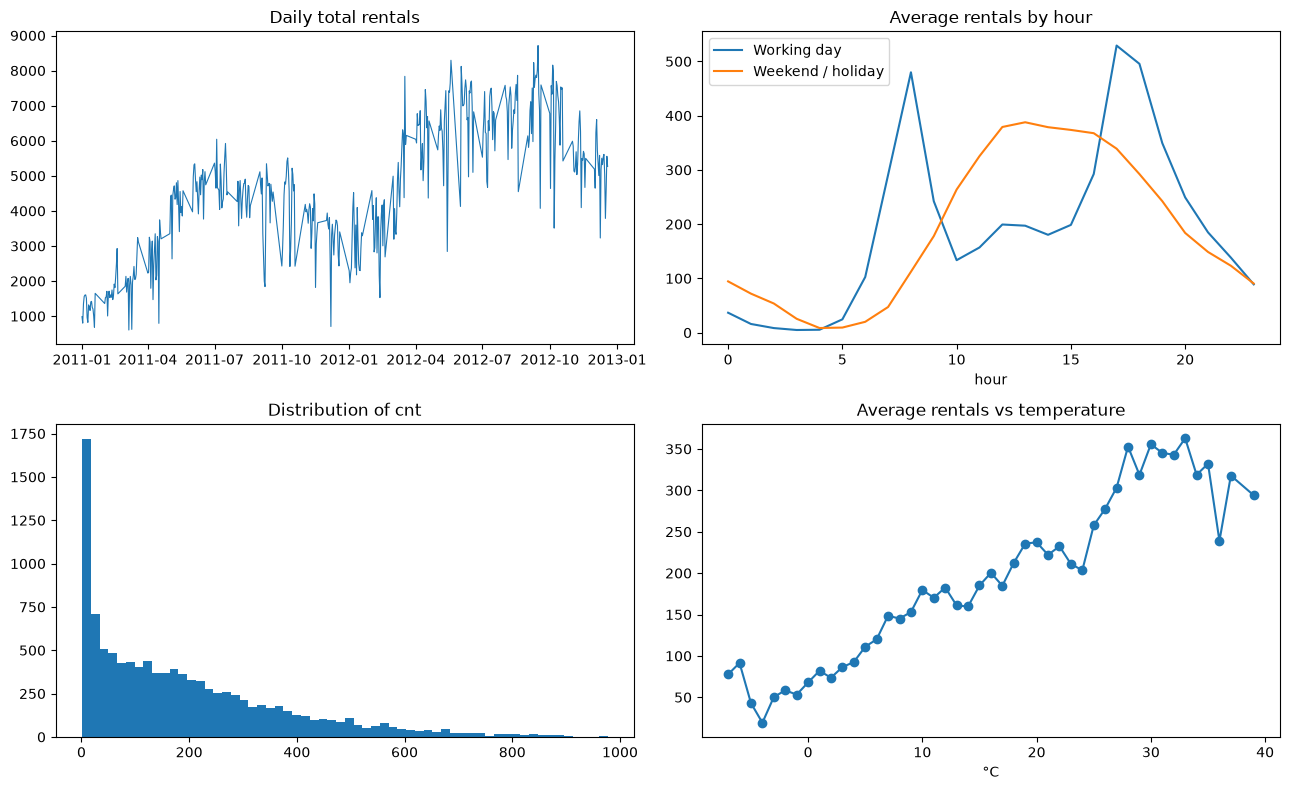

Average cnt by year: {0: 144.2, 1: 238.6}
Skewness of cnt: 1.24


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

daily = train_all.groupby("dteday")["cnt"].sum()
axes[0, 0].plot(daily.index, daily.values, linewidth=0.8)
axes[0, 0].set_title("Daily total rentals")

by_hour = train_all.groupby(["workingday", "hr"])["cnt"].mean().unstack(0)
axes[0, 1].plot(by_hour.index, by_hour[1], label="Working day")
axes[0, 1].plot(by_hour.index, by_hour[0], label="Weekend / holiday")
axes[0, 1].set_title("Average rentals by hour")
axes[0, 1].set_xlabel("hour")
axes[0, 1].legend()

axes[1, 0].hist(train_all["cnt"], bins=60)
axes[1, 0].set_title("Distribution of cnt")

temp_c = (train_all["temp"] * 47 - 8).round()          # convert back to °C
by_temp = train_all.groupby(temp_c)["cnt"].mean()
axes[1, 1].plot(by_temp.index, by_temp.values, marker="o")
axes[1, 1].set_title("Average rentals vs temperature")
axes[1, 1].set_xlabel("°C")

plt.tight_layout()
plt.savefig("figures/phase0_overview.png", dpi=120)
plt.show()

print("Average cnt by year:", train_all.groupby("yr")["cnt"].mean().round(1).to_dict())
print("Skewness of cnt:", round(train_all["cnt"].skew(), 2))

In [6]:
print("corr(temp, atemp):", round(train_all["temp"].corr(train_all["atemp"]), 3))
print(pd.crosstab(train_all["season"], train_all["mnth"]))

derived = ((train_all["weekday"].between(1, 5)) & (train_all["holiday"] == 0)).astype(int)
print("workingday = weekday + holiday rule:", (derived == train_all["workingday"]).mean())

days = (train_all["dteday"] - train_all["dteday"].min()).dt.days
print("corr(instant, days since start):", round(train_all["instant"].corr(days), 4))

corr(temp, atemp): 0.985
mnth     1    2    3    4    5    6    7    8    9    10   11   12
season                                                            
1       884  901  901    0    0    0    0    0    0    0    0    0
2         0    0    0  909  912  912    0    0    0    0    0    0
3         0    0    0    0    0    0  912  912  909    0    0    0
4         0    0    0    0    0    0    0    0    0  911  911  912
workingday = weekday + holiday rule: 1.0
corr(instant, days since start): 1.0


In [7]:
print("windspeed == 0:", (train_all["windspeed"] == 0).sum())
print("hum == 0:", (train_all["hum"] == 0).sum())
print("weathersit counts:", train_all["weathersit"].value_counts().sort_index().to_dict())
hours_per_day = train_all.groupby("dteday").size()
print("Days with fewer than 24 hours:", (hours_per_day < 24).sum(), "| minimum:", hours_per_day.min())

windspeed == 0: 1313
hum == 0: 22
weathersit counts: {1: 7192, 2: 2834, 3: 859, 4: 1}
Days with fewer than 24 hours: 42 | minimum: 12


### Phase 0 findings
1. Test set = the 20th of every month; train = days 1–19. The test is unseen whole days, not the future.
2. Working days show two rush-hour peaks (8am, 5–6pm); weekends show one midday hump → hr must interact with workingday.
3. Strong growth: average cnt 144 (2011) → 239 (2012).
4. Rentals rise with temperature and flatten/drop when very hot → non-linear.
5. cnt is right-skewed (skew 1.24).
6. Redundancy hypotheses to test in Phase 4: temp ≈ atemp (r = 0.985); season fully determined by mnth; workingday fully determined by weekday + holiday; instant = time counter.
7. Quirks: 1,313 windspeed zeros (likely missing values), 22 humidity zeros (sensor error), weathersit 4 appears once, 42 days have missing hours.


## Phase 1 – Gradient Descent (from scratch)
### Expectation
A linear model should capture the big effects (hour of day, year, weather, temperature), but not curved
relationships like "too hot reduces demand". I expect validation R² around 0.7–0.85. I expect very small
learning rates to converge slowly, and too-large ones to diverge. Because cnt is right-skewed and can't be
negative, I expect predicting log(1 + cnt) to work better than predicting cnt directly.


In [8]:
def make_features(df):
    X = pd.DataFrame(index=df.index)

    # Continuous weather columns: kept as numbers
    for col in ["temp", "atemp", "hum", "windspeed"]:
        X[col] = df[col]

    # Already 0/1 columns
    X["yr"] = df["yr"]
    X["holiday"] = df["holiday"]
    X["workingday"] = df["workingday"]

    # Categories -> one-hot (one 0/1 column per category, minus one)
    weather = df["weathersit"].replace(4, 3)          # only 1 row has 4 -> merge into 3
    for k in [2, 3]:
        X[f"weather_{k}"] = (weather == k).astype(int)
    for k in [2, 3, 4]:
        X[f"season_{k}"] = (df["season"] == k).astype(int)
    for k in range(2, 13):
        X[f"mnth_{k}"] = (df["mnth"] == k).astype(int)
    for k in range(1, 7):
        X[f"weekday_{k}"] = (df["weekday"] == k).astype(int)
    for h in range(1, 24):
        X[f"hr_{h}"] = (df["hr"] == h).astype(int)

    # Interaction: rush hour only exists on working days
    for h in range(1, 24):
        X[f"hr_{h}_x_workingday"] = ((df["hr"] == h) & (df["workingday"] == 1)).astype(int)

    return X.astype(float)

X_train_raw = make_features(train_df)
X_val_raw   = make_features(val_df)
X_test_raw  = make_features(test_X)
print(X_train_raw.shape, X_val_raw.shape, X_test_raw.shape)

(8708, 75) (2178, 75) (574, 75)


In [9]:
feat_mean = X_train_raw.mean()      # learned from TRAINING ONLY
feat_std  = X_train_raw.std()

def scale_and_add_bias(X_raw):
    X_scaled = (X_raw - feat_mean) / feat_std
    return np.c_[np.ones(len(X_scaled)), X_scaled.values]   # first column = 1 for the bias

X_train = scale_and_add_bias(X_train_raw)
X_val   = scale_and_add_bias(X_val_raw)
X_test  = scale_and_add_bias(X_test_raw)

y_train     = np.log1p(train_df["cnt"].values)   # the model learns log(1 + cnt)
y_train_cnt = train_df["cnt"].values             # real counts, for scoring
y_val_cnt   = val_df["cnt"].values

In [10]:
def gradient_descent(X, y, lr, max_iter=10000, tol=1e-7, w_init=None):
    n = len(y)
    w = np.zeros(X.shape[1]) if w_init is None else w_init.copy()
    history = []

    for i in range(max_iter):
        error = X @ w - y                  # prediction minus truth, for every row
        loss = np.mean(error ** 2)         # MSE: the number we want to minimize
        history.append(loss)

        if not np.isfinite(loss) or loss > 1e10:
            print(f"  lr={lr}: DIVERGED at iteration {i}")
            break
        if i > 0 and abs(history[-2] - loss) / history[-2] < tol:
            break                          # converged: loss stopped improving

        gradient = (2 / n) * X.T @ error   # direction in which loss increases fastest
        w = w - lr * gradient              # step the opposite way

    return w, history

def r2_score(y, p):  return 1 - np.sum((y - p) ** 2) / np.sum((y - np.mean(y)) ** 2)
def rmse(y, p):      return np.sqrt(np.mean((y - p) ** 2))
def predict_cnt(X, w): return np.expm1(X @ w)    # log prediction -> bike count

lr=0.001  iterations=10000  final loss=0.1268
lr=0.01   iterations=10000  final loss=0.1221
lr=0.1    iterations=2071   final loss=0.1220
  lr=0.3: DIVERGED at iteration 68
lr=0.3    iterations=69     final loss=10118315258.7616


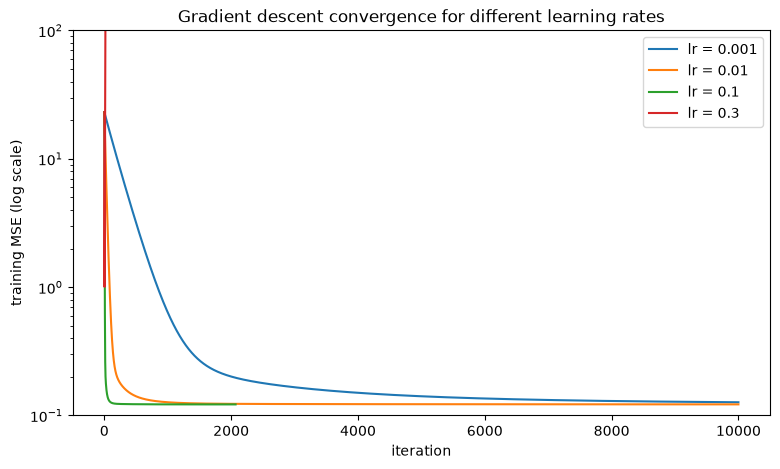

Largest stable learning rate (theory): 0.273


In [11]:
learning_rates = [0.001, 0.01, 0.1, 0.3]
histories = {}
for lr in learning_rates:
    w, hist = gradient_descent(X_train, y_train, lr)
    histories[lr] = hist
    print(f"lr={lr:<6} iterations={len(hist):<6} final loss={hist[-1]:.4f}")

plt.figure(figsize=(9, 5))
for lr, hist in histories.items():
    plt.plot(hist, label=f"lr = {lr}")
plt.yscale("log")
plt.ylim(0.1, 100)
plt.xlabel("iteration")
plt.ylabel("training MSE (log scale)")
plt.title("Gradient descent convergence for different learning rates")
plt.legend()
plt.savefig("figures/phase1_convergence.png", dpi=120)
plt.show()

H = (2 / len(y_train)) * X_train.T @ X_train
print("Largest stable learning rate (theory):", round(2 / np.linalg.eigvalsh(H).max(), 3))

In [12]:
LR = 0.1
w_phase1, hist_phase1 = gradient_descent(X_train, y_train, LR)
n_iter_phase1 = len(hist_phase1)

pred_train = predict_cnt(X_train, w_phase1)
pred_val   = predict_cnt(X_val, w_phase1)

print(f"Phase 1 | lr={LR}, iterations={n_iter_phase1}")
print(f"Train R2 = {r2_score(y_train_cnt, pred_train):.4f} | RMSE = {rmse(y_train_cnt, pred_train):.1f}")
print(f"Val   R2 = {r2_score(y_val_cnt, pred_val):.4f} | RMSE = {rmse(y_val_cnt, pred_val):.1f}")

Phase 1 | lr=0.1, iterations=2071
Train R2 = 0.8885 | RMSE = 60.7
Val   R2 = 0.8708 | RMSE = 64.4


In [13]:
# Check 1: is my gradient descent correct? Compare with the exact math solution.
w_exact, *_ = np.linalg.lstsq(X_train, y_train, rcond=None)
diff = np.abs(X_val @ w_phase1 - X_val @ w_exact).max()
print(f"Max difference between GD and exact predictions (log scale): {diff:.5f}")
print(f"Exact solution Val R2 = {r2_score(y_val_cnt, predict_cnt(X_val, w_exact)):.4f}")

# Check 2: was log(1 + cnt) really better than predicting cnt directly?
w_raw, _ = gradient_descent(X_train, y_train_cnt.astype(float), LR)
p = X_val @ w_raw
print(f"Raw-cnt model: Val R2 = {r2_score(y_val_cnt, p):.4f} | RMSE = {rmse(y_val_cnt, p):.1f} | negative predictions = {(p < 0).sum()}")
print(f"Log model    : negative predictions = {(pred_val < 0).sum()}")

Max difference between GD and exact predictions (log scale): 0.01575
Exact solution Val R2 = 0.8708
Raw-cnt model: Val R2 = 0.8262 | RMSE = 74.6 | negative predictions = 258
Log model    : negative predictions = 0


In [14]:
np.save("phase1_weights.npy", w_phase1)
phase1 = {
    "weights": w_phase1,
    "lr": LR,
    "iterations": n_iter_phase1,
    "feature_names": ["bias"] + list(X_train_raw.columns),
}
print(len(phase1["feature_names"]), "weights saved")

76 weights saved


### Outcome
Validation R² = 0.871 (RMSE 64.4), train R² = 0.889 — better than expected, mainly thanks to one-hot hours
and the hour × workingday interaction. lr = 0.1 converged in 2,071 iterations; 0.001 and 0.01 were too slow
and 0.3 diverged, matching the theoretical limit of 0.273. GD matches the exact least-squares solution.
Surprise: predicting raw cnt produced 258 negative predictions and a lower R² (0.826), confirming the log target.

## Bonus – Asymmetric loss (under-prediction costs 3×)
### Expectation
The model should shift its predictions upward, under-predicting less often, at the cost of a slightly
worse R² and RMSE (it no longer minimizes squared error). It should reduce the operator's actual cost.

### Derivation
Error for row i: eᵢ = ŷᵢ − yᵢ = xᵢ·w − yᵢ  (eᵢ < 0 means under-prediction)
Weight: cᵢ = 3 if eᵢ < 0, otherwise 1
Loss:   L(w) = (1/n) Σ cᵢ · eᵢ²
Gradient: for each row, d(cᵢ eᵢ²)/dw = 2 cᵢ eᵢ · xᵢ  (cᵢ is constant on each side of 0), so
          ∇L(w) = (2/n) Xᵀ (c ⊙ e)
At eᵢ = 0 both sides give derivative 0, so the loss is smooth everywhere and still convex.
Compared to MSE, the only change is multiplying each error by cᵢ before computing the gradient.

In [44]:
def asymmetric_gd(X, y, lr, under_cost=3.0, max_iter=20000, tol=1e-7, w_init=None):
    n = len(y)
    w = np.zeros(X.shape[1]) if w_init is None else w_init.copy()
    history = []
    for i in range(max_iter):
        error = X @ w - y
        c = np.where(error < 0, under_cost, 1.0)     # 3 for under-prediction, 1 for over
        loss = np.mean(c * error ** 2)
        history.append(loss)
        if not np.isfinite(loss) or loss > 1e10:
            print(f"DIVERGED at iteration {i}"); break
        if i > 0 and abs(history[-2] - loss) / history[-2] < tol:
            break
        gradient = (2 / n) * X.T @ (c * error)       # the derived gradient
        w = w - lr * gradient
    return w, history

def asymmetric_cost(y, p, under_cost=3.0):
    e = p - y
    return np.mean(np.where(e < 0, under_cost, 1.0) * e ** 2)

w_asym, hist_asym = asymmetric_gd(X_train, y_train, lr=0.05)
print("iterations:", len(hist_asym))

iterations: 2213


In [45]:
pred_mse  = predict_cnt(X_val, w_phase1)
pred_asym = predict_cnt(X_val, w_asym)

comparison = pd.DataFrame({
    "MSE model":        [r2_score(y_val_cnt, pred_mse),  rmse(y_val_cnt, pred_mse),
                         np.mean(pred_mse < y_val_cnt),  pred_mse.mean(),
                         asymmetric_cost(y_val_cnt, pred_mse)],
    "Asymmetric model": [r2_score(y_val_cnt, pred_asym), rmse(y_val_cnt, pred_asym),
                         np.mean(pred_asym < y_val_cnt), pred_asym.mean(),
                         asymmetric_cost(y_val_cnt, pred_asym)]},
    index=["val R2", "val RMSE", "share under-predicted", "mean prediction",
           "asymmetric cost (bikes²)"]).round(3)
print("Actual mean on validation:", round(y_val_cnt.mean(), 1))
comparison

Actual mean on validation: 188.8


,MSE model,Asymmetric model
val R2,0.871,0.842
val RMSE,64.365,71.214
share under-predicted,0.555,0.384
mean prediction,184.871,204.301
asymmetric cost (bikes²),7885.765,6989.845


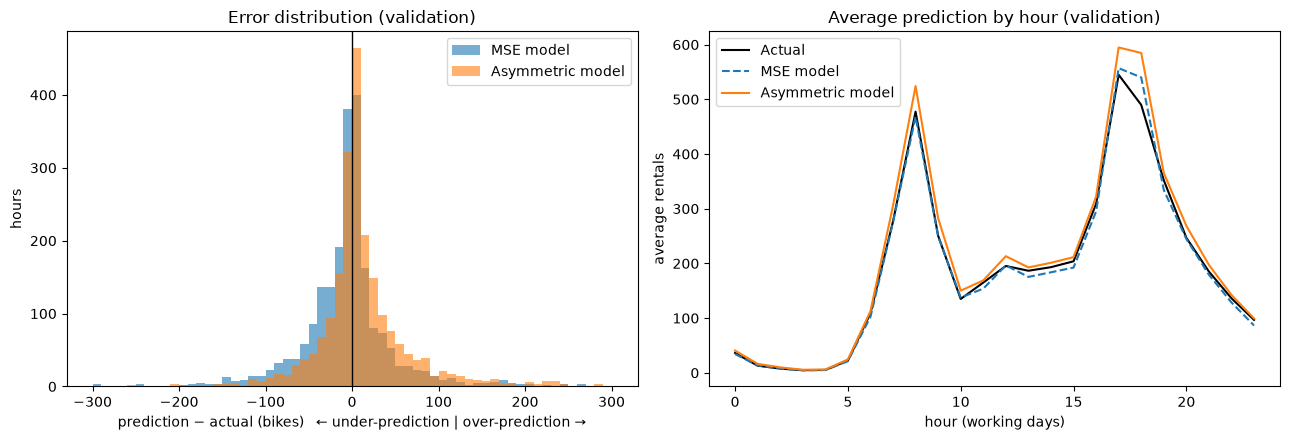

      cnt    mse   asym
hr                     
8   477.0  468.0  524.0
17  545.0  557.0  595.0


In [47]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(-300, 300, 61)
axes[0].hist(pred_mse - y_val_cnt, bins=bins, alpha=0.6, label="MSE model")
axes[0].hist(pred_asym - y_val_cnt, bins=bins, alpha=0.6, label="Asymmetric model")
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_xlabel("prediction − actual (bikes)   ← under-prediction | over-prediction →")
axes[0].set_ylabel("hours")
axes[0].set_title("Error distribution (validation)")
axes[0].legend()

v = val_df.assign(mse=pred_mse, asym=pred_asym)
by_hr = v[v["workingday"] == 1].groupby("hr")[["cnt", "mse", "asym"]].mean()
axes[1].plot(by_hr.index, by_hr["cnt"], "k-", label="Actual")
axes[1].plot(by_hr.index, by_hr["mse"], "--", label="MSE model")
axes[1].plot(by_hr.index, by_hr["asym"], "-", label="Asymmetric model")
axes[1].set_xlabel("hour (working days)")
axes[1].set_ylabel("average rentals")
axes[1].set_title("Average prediction by hour (validation)")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/bonus_asymmetric.png", dpi=120)
plt.show()
print(by_hr.loc[[8, 17]].round(0))

### Outcome
The asymmetric model shifted predictions upward by ~10% (mean 184.9 → 204.3 bikes vs actual 188.8),
cutting the share of under-predicted hours from 55.5% to 38.4%. R² fell (0.871 → 0.842) and RMSE rose
(64.4 → 71.2), as expected, since it no longer minimizes squared error — but the operator's asymmetric
cost on validation fell by 11% (7,886 → 6,990). Because the model works on log(1 + cnt), the shift is
proportional: almost none at night, ~50 extra bikes at the 8am and 5pm peaks. learning rate 0.05 was used
because the 3× weight can triple the gradient, lowering the stability limit to ≈0.273 / 3 = 0.091.

## Phase 2 – Polynomial Regression
### Expectation
Adding squared terms for temperature should help, because demand rises then falls as it gets hotter.
I expect a clear gain from degree 1 to 2, smaller gains after that, and eventually overfitting
(train R² keeps rising while validation R² stops or drops). Higher degrees should also make
gradient descent slower, because x, x² and x³ are strongly correlated.

In [15]:
from itertools import combinations_with_replacement

POLY_COLS = ["temp", "hum", "windspeed"]

def add_polynomial(X_raw, df, degree):
    X = X_raw.copy()
    for d in range(2, degree + 1):
        for combo in combinations_with_replacement(POLY_COLS, d):
            name = "*".join(combo)
            X[name] = np.prod([df[c].values for c in combo], axis=0)
    return X

print(list(add_polynomial(X_train_raw, train_df, 2).columns[75:]))

['temp*temp', 'temp*hum', 'temp*windspeed', 'hum*hum', 'hum*windspeed', 'windspeed*windspeed']


In [16]:
def prepare_degree(degree):
    Xtr = add_polynomial(X_train_raw, train_df, degree)
    Xva = add_polynomial(X_val_raw, val_df, degree)
    Xte = add_polynomial(X_test_raw, test_X, degree)
    mean, std = Xtr.mean(), Xtr.std()                     # training statistics only
    to_matrix = lambda X: np.c_[np.ones(len(X)), ((X - mean) / std).values]
    return to_matrix(Xtr), to_matrix(Xva), to_matrix(Xte), list(Xtr.columns)

def init_from_phase1(n_features):
    w0 = np.zeros(n_features)
    w0[:len(phase1["weights"])] = phase1["weights"]       # copy Phase 1's 76 weights
    return w0                                             # new polynomial columns start at 0

In [17]:
results = []
models = {}

for degree in range(1, 6):
    A_tr, A_va, A_te, names = prepare_degree(degree)

    # stay below the stability limit (it shrinks as degree grows)
    H = (2 / len(y_train)) * A_tr.T @ A_tr
    lr = min(phase1["lr"], 0.9 * 2 / np.linalg.eigvalsh(H).max())

    w, hist = gradient_descent(A_tr, y_train, lr, max_iter=20000,
                               w_init=init_from_phase1(A_tr.shape[1]))

    p_tr, p_va = predict_cnt(A_tr, w), predict_cnt(A_va, w)
    results.append({"degree": degree, "n_features": A_tr.shape[1] - 1, "lr": round(lr, 3),
                    "iterations": len(hist),
                    "train_R2": r2_score(y_train_cnt, p_tr), "val_R2": r2_score(y_val_cnt, p_va),
                    "train_RMSE": rmse(y_train_cnt, p_tr), "val_RMSE": rmse(y_val_cnt, p_va)})
    models[degree] = {"w": w, "names": names, "hist": hist}

results_df = pd.DataFrame(results).round(4)
results_df

,degree,n_features,lr,iterations,train_R2,val_R2,train_RMSE,val_RMSE
0,1,75,0.100,2,0.8885,0.8708,60.6526,64.3647
1,2,81,0.100,3460,0.9082,0.8998,55.0291,56.6777
2,3,91,0.100,12751,0.9116,0.9047,53.9969,55.2642
3,4,106,0.060,20000,0.9123,0.9053,53.7886,55.1041
4,5,127,0.037,20000,0.9128,0.9059,53.6540,54.9190


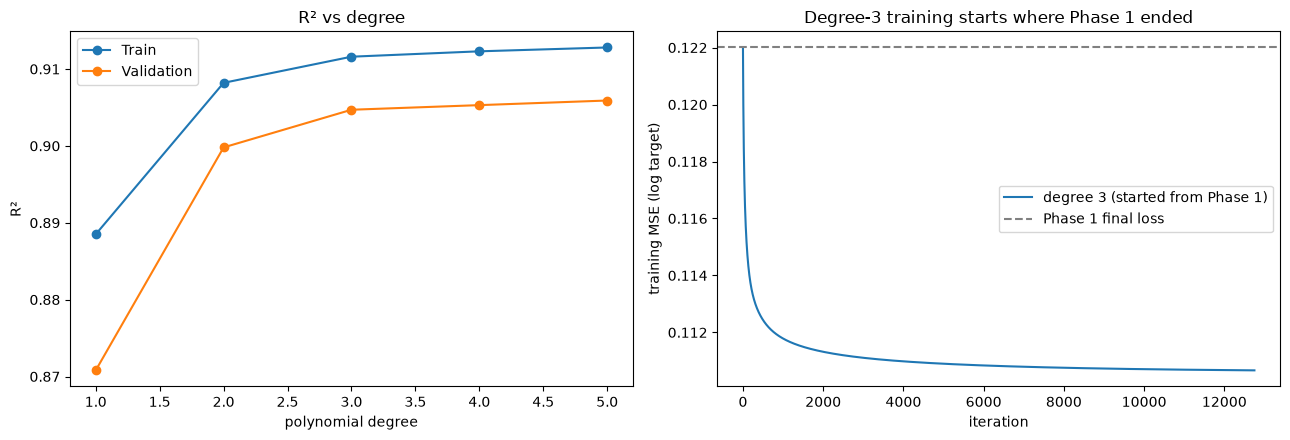

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(results_df["degree"], results_df["train_R2"], "o-", label="Train")
axes[0].plot(results_df["degree"], results_df["val_R2"], "o-", label="Validation")
axes[0].set_xlabel("polynomial degree")
axes[0].set_ylabel("R²")
axes[0].set_title("R² vs degree")
axes[0].legend()

axes[1].plot(models[3]["hist"], label="degree 3 (started from Phase 1)")
axes[1].axhline(min(hist_phase1), color="gray", linestyle="--", label="Phase 1 final loss")
axes[1].set_xlabel("iteration")
axes[1].set_ylabel("training MSE (log target)")
axes[1].set_title("Degree-3 training starts where Phase 1 ended")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/phase2_degree.png", dpi=120)
plt.show()

In [19]:
CHOSEN_DEGREE = 3

w_phase2 = models[CHOSEN_DEGREE]["w"]
phase2_features = models[CHOSEN_DEGREE]["names"]
chosen = results_df[results_df.degree == CHOSEN_DEGREE].iloc[0]

phase2 = {
    "degree": CHOSEN_DEGREE,
    "expanded_columns": POLY_COLS,
    "feature_names": ["bias"] + phase2_features,
    "weights": w_phase2,
    "train_R2": chosen.train_R2,
    "val_R2": chosen.val_R2,
}
print(chosen.to_dict())

{'degree': 3.0, 'n_features': 91.0, 'lr': 0.1, 'iterations': 12751.0, 'train_R2': 0.9116, 'val_R2': 0.9047, 'train_RMSE': 53.9969, 'val_RMSE': 55.2642}


### Outcome
Polynomial terms helped: validation R² 0.871 → 0.900 at degree 2 and 0.905 at degree 3 (RMSE 64.4 → 55.3).
Degrees 4–5 added only ~0.001 while requiring smaller learning rates and failing to converge within
20,000 iterations, so degree 3 was chosen. Surprise: no overfitting appeared — the train/validation
gap stayed ≈0.007 at every degree. Only 3 continuous columns were expanded, so complexity stays
modest; Phase 3 must check whether the random split is hiding a problem.

## Phase 3 – Bias-Variance Tradeoff
### Expectation
Phase 2 showed a small train/validation gap (~0.007) at every degree, so I expect the model is not
overfitting. I expect the learning curve to show the gap shrinking as data grows. For the chronological
split I expect a clearly lower score, because the random split mixes hours from the same day into
training and validation, while the chronological split forces the model to predict a later period.

In [20]:
def fit_pipeline(tr_df, va_df, degree, max_iter=20000):
    Xtr = add_polynomial(make_features(tr_df), tr_df, degree)
    Xva = add_polynomial(make_features(va_df), va_df, degree)
    mean, std = Xtr.mean(), Xtr.std().replace(0, 1)
    A_tr = np.c_[np.ones(len(Xtr)), ((Xtr - mean) / std).values]
    A_va = np.c_[np.ones(len(Xva)), ((Xva - mean) / std).values]
    y_tr = np.log1p(tr_df["cnt"].values)

    H = (2 / len(y_tr)) * A_tr.T @ A_tr
    lr = min(0.1, 0.9 * 2 / np.linalg.eigvalsh(H).max())
    w, hist = gradient_descent(A_tr, y_tr, lr, max_iter=max_iter)

    p_tr, p_va = predict_cnt(A_tr, w), predict_cnt(A_va, w)
    return {"train_R2": r2_score(tr_df["cnt"].values, p_tr),
            "val_R2": r2_score(va_df["cnt"].values, p_va),
            "train_RMSE": rmse(tr_df["cnt"].values, p_tr),
            "val_RMSE": rmse(va_df["cnt"].values, p_va),
            "iterations": len(hist), "pred_val": p_va}

r = fit_pipeline(train_df, val_df, 3)
print(round(r["val_R2"], 4))

0.9047


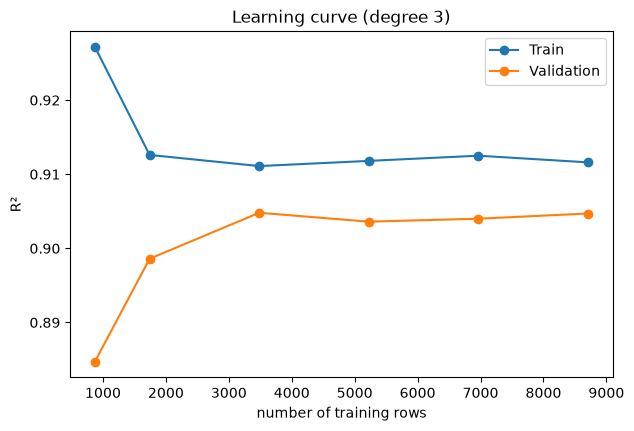

,n_train,train_R2,val_R2
0,870,0.9272,0.8847
1,1741,0.9126,0.8986
2,3483,0.9111,0.9048
3,5224,0.9118,0.9036
4,6966,0.9125,0.9040
5,8708,0.9116,0.9047


In [21]:
fractions = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
lc = []
for f in fractions:
    sub = train_df.iloc[: int(f * len(train_df))]      # train_df is already shuffled by the split
    r = fit_pipeline(sub, val_df, CHOSEN_DEGREE)
    lc.append({"n_train": len(sub), "train_R2": r["train_R2"], "val_R2": r["val_R2"]})
lc_df = pd.DataFrame(lc).round(4)

plt.figure(figsize=(7, 4.5))
plt.plot(lc_df["n_train"], lc_df["train_R2"], "o-", label="Train")
plt.plot(lc_df["n_train"], lc_df["val_R2"], "o-", label="Validation")
plt.xlabel("number of training rows")
plt.ylabel("R²")
plt.title(f"Learning curve (degree {CHOSEN_DEGREE})")
plt.legend()
plt.savefig("figures/phase3_learning_curve.png", dpi=120)
plt.show()
lc_df

8607 2279 0.209


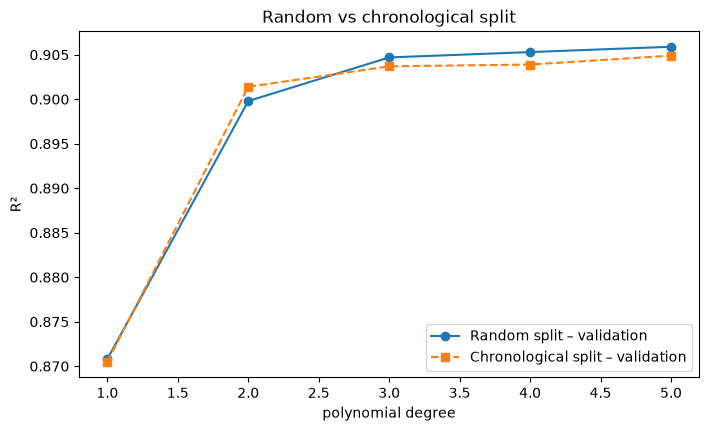

,degree,random_train_R2,random_val_R2,random_val_RMSE,chrono_train_R2,chrono_val_R2,chrono_val_RMSE
0,1,0.8885,0.8708,64.3647,0.8700,0.8705,78.4199
1,2,0.9082,0.8998,56.6771,0.8942,0.9014,68.4170
2,3,0.9116,0.9047,55.2703,0.8992,0.9037,67.6073
3,4,0.9123,0.9053,55.1041,0.9000,0.9039,67.5413
4,5,0.9128,0.9059,54.9169,0.9005,0.9049,67.1983


In [22]:
CUTOFF = pd.Timestamp("2012-08-01")
chrono_train = train_all[train_all["dteday"] < CUTOFF]
chrono_val   = train_all[train_all["dteday"] >= CUTOFF]
print(len(chrono_train), len(chrono_val), round(len(chrono_val) / len(train_all), 3))

rows = []
for degree in range(1, 6):
    r_rand = fit_pipeline(train_df, val_df, degree)
    r_time = fit_pipeline(chrono_train, chrono_val, degree)
    rows.append({"degree": degree,
                 "random_train_R2": r_rand["train_R2"], "random_val_R2": r_rand["val_R2"],
                 "random_val_RMSE": r_rand["val_RMSE"],
                 "chrono_train_R2": r_time["train_R2"], "chrono_val_R2": r_time["val_R2"],
                 "chrono_val_RMSE": r_time["val_RMSE"]})
compare_df = pd.DataFrame(rows).round(4)

plt.figure(figsize=(8, 4.5))
plt.plot(compare_df["degree"], compare_df["random_val_R2"], "o-", label="Random split – validation")
plt.plot(compare_df["degree"], compare_df["chrono_val_R2"], "s--", label="Chronological split – validation")
plt.xlabel("polynomial degree")
plt.ylabel("R²")
plt.title("Random vs chronological split")
plt.legend()
plt.savefig("figures/phase3_random_vs_chrono.png", dpi=120)
plt.show()
compare_df

In [23]:
r_time = fit_pipeline(chrono_train, chrono_val, CHOSEN_DEGREE)
diag = chrono_val.assign(pred=r_time["pred_val"])
monthly = diag.groupby(diag["dteday"].dt.to_period("M")).agg(
    actual=("cnt", "mean"), predicted=("pred", "mean")).round(1)
print(monthly)
print("Average error (actual - predicted):", round((diag["cnt"] - diag["pred"]).mean(), 1))

         actual  predicted
dteday                    
2012-08   285.6      307.2
2012-09   292.6      302.7
2012-10   280.5      299.8
2012-11   232.0      246.1
2012-12   217.1      230.0
Average error (actual - predicted): -15.6


In [24]:
d19_train = train_all[train_all["dteday"].dt.day <= 18]
d19_val   = train_all[train_all["dteday"].dt.day == 19]
r19 = fit_pipeline(d19_train, d19_val, CHOSEN_DEGREE)
print(len(d19_train), len(d19_val))
print(f"Train R2 = {r19['train_R2']:.4f} | Val R2 = {r19['val_R2']:.4f} | Val RMSE = {r19['val_RMSE']:.1f}")

10312 574
Train R2 = 0.9108 | Val R2 = 0.8910 | Val RMSE = 59.5


In [25]:
phase3 = {
    "diagnosis": "reasonably fit, slight bias; no overfitting",
    "target_degree": 3,
    "random_val_R2": 0.9047, "random_val_RMSE": 55.3,
    "day19_val_R2": round(r19["val_R2"], 4), "day19_val_RMSE": round(r19["val_RMSE"], 1),
    "chrono_val_R2": 0.9037, "chrono_val_RMSE": 67.6,
}
phase3

{'diagnosis': 'reasonably fit, slight bias; no overfitting',
 'target_degree': 3,
 'random_val_R2': 0.9047,
 'random_val_RMSE': 55.3,
 'day19_val_R2': 0.891,
 'day19_val_RMSE': 59.5,
 'chrono_val_R2': 0.9037,
 'chrono_val_RMSE': 67.6}

### Outcome
Diagnosis: reasonably fit with slight bias, no overfitting. Evidence: train/val gap ≈0.007 at degree 3;
the learning curve gap shrinks from 0.043 (870 rows) to 0.007 (8,708 rows) and both curves plateau at ~0.905.
Surprise: the chronological split gave almost the same R² (0.904 vs 0.905) but RMSE rose from 55.3 to 67.6,
because late 2012 has higher variance; the model systematically over-predicted Aug–Dec 2012 by ~16 bikes/hour
since it extrapolated the 2012 growth rate. A day-19 split (matching the test set's day-20 structure) gave
R² 0.891 / RMSE 59.5, showing the random split is optimistic due to same-day leakage.
Target degree carried to Phase 4: 3.

## Phase 4 – Regularization (L1, L2, Elastic Net)
### Expectation
Phase 3 found no overfitting, so I expect regularization to change validation R² very little.
Lasso should zero out redundant features — I expect atemp (duplicates temp), season (duplicates mnth)
and possibly holiday/weekday (overlap with workingday) to lose their weights first.
Large λ values should hurt accuracy because they force away useful weights (underfitting).

In [26]:
A_tr, A_va, A_te, names = prepare_degree(CHOSEN_DEGREE)
feature_names = ["bias"] + names
y_val_log = np.log1p(y_val_cnt)

def regularized_gd(X, y, lr, lam, l1_ratio, max_iter=5000, tol=1e-7, w_init=None):
    n = len(y)
    w = np.zeros(X.shape[1]) if w_init is None else w_init.copy()
    lam_l1 = lam * l1_ratio              # strength of the Lasso part
    lam_l2 = lam * (1 - l1_ratio)        # strength of the Ridge part
    prev = None
    for i in range(max_iter):
        error = X @ w - y
        grad = (2 / n) * X.T @ error     # same MSE gradient as Phase 1
        grad[1:] += lam_l2 * w[1:]       # Ridge part: pulls every weight toward 0 (not the bias)
        w = w - lr * grad
        # Lasso part ("soft-thresholding"): shrink each weight by lr*lam_l1; if it crosses 0, set it to 0
        w[1:] = np.sign(w[1:]) * np.maximum(np.abs(w[1:]) - lr * lam_l1, 0)
        loss = np.mean(error ** 2) + lam_l1 * np.abs(w[1:]).sum() + 0.5 * lam_l2 * np.sum(w[1:] ** 2)
        if prev is not None and abs(prev - loss) / prev < tol:
            break
        prev = loss
    return w, i + 1

In [27]:
lambdas = [1e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
methods = {"Ridge": [0.0], "Lasso": [1.0], "ElasticNet": [0.2, 0.5, 0.8]}

search = []
weights = {}
for method, ratios in methods.items():
    for l1_ratio in ratios:
        w_start = phase2["weights"]                    # chain: start from Phase 2's model
        for lam in lambdas:
            w, n_it = regularized_gd(A_tr, y_train, 0.1, lam, l1_ratio, w_init=w_start)
            w_start = w                                # warm start for the next λ
            search.append({"method": method, "l1_ratio": l1_ratio, "lambda": lam,
                           "train_R2": r2_score(y_train_cnt, predict_cnt(A_tr, w)),
                           "val_R2": r2_score(y_val_cnt, predict_cnt(A_va, w)),
                           "val_RMSE": rmse(y_val_cnt, predict_cnt(A_va, w)),
                           "nonzero": int((w[1:] != 0).sum())})
            weights[(method, l1_ratio, lam)] = w

search_df = pd.DataFrame(search).round(4)
best = (search_df.sort_values(["val_R2", "lambda"], ascending=[False, False])
                 .groupby("method").head(1).set_index("method"))
best

,l1_ratio,lambda,train_R2,val_R2,val_RMSE,nonzero
method,,,,,,
Lasso,1.0,0.0010,0.9120,0.9051,55.1655,82
ElasticNet,0.5,0.0003,0.9120,0.9051,55.1696,91
Ridge,0.0,0.0010,0.9119,0.9050,55.1788,91


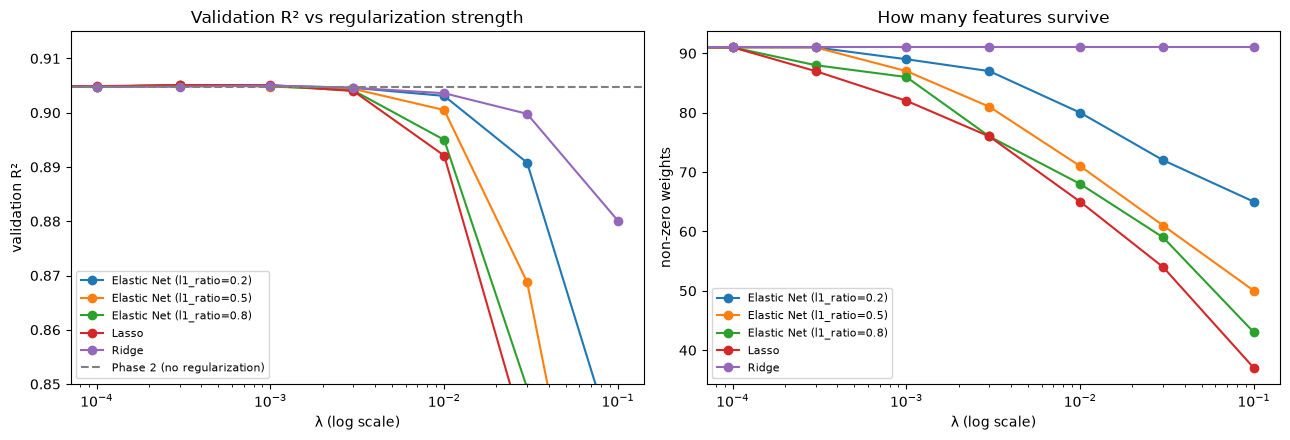

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (method, ratio), grp in search_df.groupby(["method", "l1_ratio"]):
    label = method if method != "ElasticNet" else f"Elastic Net (l1_ratio={ratio})"
    axes[0].plot(grp["lambda"], grp["val_R2"], "o-", label=label)
    axes[1].plot(grp["lambda"], grp["nonzero"], "o-", label=label)
axes[0].axhline(phase2["val_R2"], color="gray", linestyle="--", label="Phase 2 (no regularization)")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("λ (log scale)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("validation R²")
axes[0].set_title("Validation R² vs regularization strength")
axes[0].set_ylim(0.85, 0.915)
axes[1].set_ylabel("non-zero weights")
axes[1].set_title("How many features survive")
plt.tight_layout()
plt.savefig("figures/phase4_regularization.png", dpi=120)
plt.show()

In [29]:
def column_of(name):
    """Which original column(s) a feature comes from."""
    if name == "bias": return set()
    if "*" in name: return set(name.split("*"))                       # e.g. temp*hum
    if name.startswith("hr_") and name.endswith("_x_workingday"): return {"hr", "workingday"}
    prefixes = {"weather_": "weathersit", "season_": "season", "mnth_": "mnth",
                "weekday_": "weekday", "hr_": "hr"}
    for prefix, col in prefixes.items():
        if name.startswith(prefix): return {col}
    return {name}

COLUMNS = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday",
           "weathersit", "temp", "atemp", "hum", "windspeed"]
path = {}
for lam in [1e-3, 3e-3, 1e-2]:
    w = weights[("Lasso", 1.0, lam)]
    path[f"λ={lam}"] = {c: f"{sum(1 for i in range(1, len(w)) if c in column_of(feature_names[i]) and w[i] != 0)}"
                           f"/{sum(1 for i in range(1, len(w)) if c in column_of(feature_names[i]))}"
                        for c in COLUMNS}
pd.DataFrame(path)

,λ=0.001,λ=0.003,λ=0.01
season,3/3,3/3,3/3
yr,1/1,1/1,1/1
mnth,8/11,8/11,4/11
hr,45/46,45/46,39/46
holiday,1/1,0/1,0/1
weekday,6/6,6/6,5/6
workingday,24/24,23/24,18/24
weathersit,2/2,2/2,2/2
temp,6/10,4/10,4/10
atemp,1/1,1/1,1/1


In [30]:
LAM, RATIO = 1e-3, 1.0                     # the chosen Lasso
w_base, _ = regularized_gd(A_tr, y_train, 0.1, LAM, RATIO, w_init=phase2["weights"])
base_r2 = r2_score(y_val_cnt, predict_cnt(A_va, w_base))
base_log_mse = np.mean((A_va @ w_base - y_val_log) ** 2)

def keep_without(cols):
    return [0] + [i for i in range(1, len(feature_names)) if not (column_of(feature_names[i]) & set(cols))]

def drop_test(cols):
    keep = keep_without(cols)
    w, _ = regularized_gd(A_tr[:, keep], y_train, 0.1, LAM, RATIO, w_init=phase2["weights"][keep])
    return {"dropped": " + ".join(cols),
            "features_removed": len(feature_names) - len(keep),
            "change_val_R2": r2_score(y_val_cnt, predict_cnt(A_va[:, keep], w)) - base_r2,
            "change_log_MSE": np.mean((A_va[:, keep] @ w - y_val_log) ** 2) - base_log_mse}

groups = [["atemp"], ["temp"], ["temp", "atemp"], ["season"], ["mnth"], ["season", "mnth"],
          ["holiday"], ["weekday"], ["weekday", "holiday"], ["windspeed"], ["hum"],
          ["weathersit"], ["yr"], ["workingday"], ["hr"]]
drop_df = pd.DataFrame([drop_test(g) for g in groups]).round(4)
print(drop_df.to_string())

# instant was never used — test whether adding it would help
inst_mean, inst_std = train_df["instant"].mean(), train_df["instant"].std()
I_tr = np.c_[A_tr, (train_df["instant"].values - inst_mean) / inst_std]
I_va = np.c_[A_va, (val_df["instant"].values - inst_mean) / inst_std]
w_inst, _ = regularized_gd(I_tr, y_train, 0.1, LAM, RATIO, w_init=np.r_[phase2["weights"], 0])
print("Adding instant changes val R2 by:", round(r2_score(y_val_cnt, predict_cnt(I_va, w_inst)) - base_r2, 4))

              dropped  features_removed  change_val_R2  change_log_MSE
0               atemp                 1        -0.0001          0.0000
1                temp                10        -0.0243          0.0071
2        temp + atemp                11        -0.0254          0.0173
3              season                 3        -0.0000          0.0000
4                mnth                11         0.0006          0.0024
5       season + mnth                14        -0.0197          0.0238
6             holiday                 1        -0.0000          0.0000
7             weekday                 6         0.0068          0.0035
8   weekday + holiday                 7         0.0066          0.0034
9           windspeed                10        -0.0024          0.0044
10                hum                10        -0.0091          0.0065
11         weathersit                 2        -0.0039          0.0100
12                 yr                 1        -0.0955          0.0493
13    

### Verdict for every original column
| Column | Verdict | Evidence |
|---|---|---|
| hr | Useful (most important) | Dropping it: val R² −0.680 |
| workingday | Useful | Dropping it (incl. hr×workingday): −0.163 |
| yr | Useful | Dropping it: −0.096 (captures 2011→2012 growth) |
| temp | Useful | Dropping it: −0.024 |
| hum | Useful | Dropping it: −0.009 |
| weathersit | Useful | Dropping it: −0.004; both categories kept by Lasso at every λ |
| windspeed | Useful but weak | Dropping it: −0.002; Lasso zeroes its linear term at λ=0.003 (1,313 zero readings likely missing) |
| mnth | Useful (but overlaps season) | Alone: +0.0006; with season: −0.020 |
| atemp | Redundant (carried by temp) | Dropping it: −0.0001; r = 0.985 with temp; temp+atemp together: −0.025 |
| season | Redundant (carried by mnth) | Dropping it: 0.0000; each season = exactly 3 months; season+mnth together: −0.020 |
| holiday | Redundant (carried by workingday) | Dropping it: 0.0000; first column Lasso removes (λ=0.003); workingday = weekday+holiday rule in 100% of rows |
| weekday | Redundant (carried by workingday) and harmful | Dropping it: +0.007 val R² |
| instant | Redundant (time already in yr + mnth) | Adding it: −0.0001; correlation 1.0 with date |
| dteday | Redundant as a raw column | Not usable as text; its useful content (year, month) is already in yr and mnth |

In [31]:
DROP_COLUMNS = ["atemp", "season", "holiday", "weekday"]
keep = keep_without(DROP_COLUMNS)
final_names = [feature_names[i] for i in keep]
R_tr, R_va, R_te = A_tr[:, keep], A_va[:, keep], A_te[:, keep]
w_init = phase2["weights"][keep]

final_rows = []
final_weights = {}
for method, ratio in [("Ridge", 0.0), ("Lasso", 1.0), ("ElasticNet", 0.5)]:
    w_start = w_init
    for lam in [1e-4, 3e-4, 1e-3, 3e-3]:
        w, _ = regularized_gd(R_tr, y_train, 0.1, lam, ratio, w_init=w_start)
        w_start = w
        final_rows.append({"method": method, "l1_ratio": ratio, "lambda": lam,
                           "train_R2": r2_score(y_train_cnt, predict_cnt(R_tr, w)),
                           "val_R2": r2_score(y_val_cnt, predict_cnt(R_va, w)),
                           "val_RMSE": rmse(y_val_cnt, predict_cnt(R_va, w)),
                           "nonzero": int((w[1:] != 0).sum())})
        final_weights[(method, lam)] = w

final_df = pd.DataFrame(final_rows).round(4)
final_best = (final_df.sort_values(["val_R2", "lambda"], ascending=[False, False])
                      .groupby("method").head(1).set_index("method"))
final_best

,l1_ratio,lambda,train_R2,val_R2,val_RMSE,nonzero
method,,,,,,
Lasso,1.0,0.001,0.9159,0.9116,53.2358,75
ElasticNet,0.5,0.001,0.9160,0.9116,53.2459,80
Ridge,0.0,0.001,0.9161,0.9114,53.2965,80


In [32]:
w_final = final_weights[("Lasso", 1e-3)]
surviving_features = [n for n, wt in zip(final_names, w_final) if n != "bias" and wt != 0]
surviving_columns = sorted({c for n in surviving_features for c in column_of(n)})
print(len(surviving_features), "features survive from columns:", surviving_columns)
print("Zeroed by Lasso:", [n for n, wt in zip(final_names, w_final) if n != "bias" and wt == 0])

phase4 = {"best_lambda": {"Ridge": 1e-3, "Lasso": 1e-3, "ElasticNet": (1e-3, 0.5)},
          "final_method": "Lasso", "final_lambda": 1e-3,
          "surviving_features": surviving_features, "surviving_columns": surviving_columns}

# Final test predictions from the recommended regression model
test_pred = np.round(predict_cnt(R_te, w_final)).astype(int)
sub = pd.read_csv("data/sample_submission.csv")
assert (sub["instant"].values == test_X["instant"].values).all()   # same row order
sub["cnt"] = test_pred
sub.to_csv("sample_submission.csv", index=False)
sub.head()

75 features survive from columns: ['hr', 'hum', 'mnth', 'temp', 'weathersit', 'windspeed', 'workingday', 'yr']
Zeroed by Lasso: ['hr_23', 'temp*hum', 'temp*windspeed', 'hum*hum', 'temp*temp*hum']


,instant,cnt
0,432,12
1,433,5
2,434,2
3,435,1
4,436,2


### Outcome
As expected, regularization alone barely changed accuracy (val R² 0.9047 → 0.9051 for all three methods),
confirming Phase 3's "no overfitting" diagnosis. Its real value was feature selection: Lasso (λ=0.001)
matched Ridge and Elastic Net using 82 instead of 91 features, and the drop-column tests proved atemp,
season, holiday and weekday redundant. Surprise: dropping weekday improved count-scale R² (+0.007) even though
it slightly helped on the log scale. After removing the four redundant columns, all methods improved
to val R² 0.912 / RMSE 53.2. Final model: Lasso λ=0.001, 75 features from 8 columns
(hr, workingday, yr, mnth, weathersit, temp, hum, windspeed) — these go to Phase 5.

## Phase 5 – Logistic Regression
### Expectation
If "high demand" is defined with one global threshold, I expect the classifier to mostly learn the
hour of day (rush hours are always high, nights never), which is useless to the operator. A threshold
relative to each time slot should remove that, making the task harder (lower AUC) but more meaningful.
With ~25% positives, accuracy will be misleading, so I'll rely on F1 and ROC-AUC.

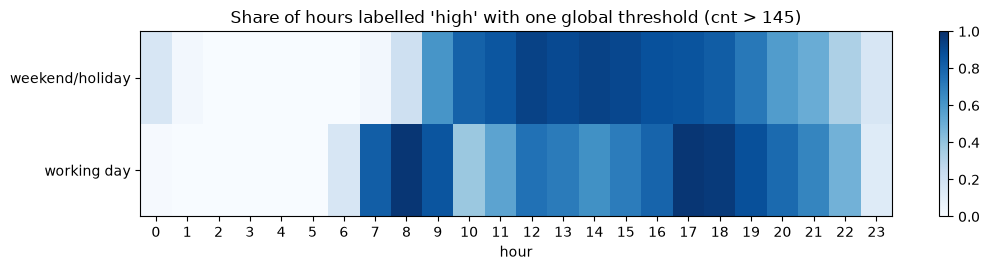

hr           3     8     12    17
workingday                       
0           0.0  0.21  0.93  0.86
1           0.0  0.98  0.75  0.98
By year: {0: 0.404, 1: 0.593}


In [33]:
median_cnt = train_df["cnt"].median()
y_global_train = (train_df["cnt"] > median_cnt).astype(int)
rate = y_global_train.groupby([train_df["workingday"], train_df["hr"]]).mean().unstack("hr")

fig, ax = plt.subplots(figsize=(11, 2.8))
im = ax.imshow(rate.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_yticks([0, 1]); ax.set_yticklabels(["weekend/holiday", "working day"])
ax.set_xticks(range(24)); ax.set_xlabel("hour")
ax.set_title(f"Share of hours labelled 'high' with one global threshold (cnt > {median_cnt:.0f})")
plt.colorbar(im); plt.tight_layout()
plt.savefig("figures/phase5_global_threshold.png", dpi=120)
plt.show()

print(rate.round(2).loc[:, [3, 8, 12, 17]])
print("By year:", y_global_train.groupby(train_df["yr"]).mean().round(3).to_dict())

In [34]:
SLOT = ["yr", "hr", "workingday"]
slot_threshold = train_df.groupby(SLOT)["cnt"].quantile(0.75).rename("threshold")   # TRAINING ONLY

def high_demand_label(df):
    thr = df.join(slot_threshold, on=SLOT)["threshold"]
    return (df["cnt"] > thr).astype(int).values

y5_train = high_demand_label(train_df)
y5_val   = high_demand_label(val_df)
print(f"High-demand share: train {y5_train.mean():.3f} | val {y5_val.mean():.3f}")
print("By year:", pd.Series(y5_train).groupby(train_df["yr"].values).mean().round(3).to_dict())

High-demand share: train 0.245 | val 0.261
By year: {0: 0.244, 1: 0.245}


In [37]:
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score, confusion_matrix, roc_curve

# Keep only the features that survived Phase 4's Lasso (plus the bias column)
surv_idx = [0] + [j for j, n in enumerate(final_names) if n != "bias" and w_final[j] != 0]
surviving_features = [final_names[j] for j in surv_idx[1:]]
C_tr, C_va = R_tr[:, surv_idx], R_va[:, surv_idx]
print(C_tr.shape)

(8708, 76)


In [38]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def logistic_gd(X, y, lr, max_iter=20000, tol=1e-6):
    n = len(y)
    w = np.zeros(X.shape[1])
    history = []
    for i in range(max_iter):
        p = sigmoid(X @ w)                                   # predicted probabilities
        loss = -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))
        history.append(loss)
        if i > 0 and abs(history[-2] - loss) / history[-2] < tol:
            break
        w = w - lr * (X.T @ (p - y)) / n                     # gradient of cross-entropy
    return w, history

w_logit, hist_logit = logistic_gd(C_tr, y5_train, lr=1.0)
print("iterations:", len(hist_logit), "| final loss:", round(hist_logit[-1], 4))

iterations: 2086 | final loss: 0.3984


In [39]:
surv_idx = [0] + [j for j, n in enumerate(final_names) if n != "bias" and w_final[j] != 0]
surviving_features = [final_names[j] for j in surv_idx[1:]]
C_tr, C_va = R_tr[:, surv_idx], R_va[:, surv_idx]
print(C_tr.shape)          # (8708, 76) = bias + 75 surviving features

(8708, 76)


In [40]:
p_train = sigmoid(C_tr @ w_logit)
p_val   = sigmoid(C_va @ w_logit)

cands = np.arange(0.10, 0.91, 0.01)
f1_train = [f1_score(y5_train, p_train >= c) for c in cands]
BEST_CUT = round(cands[int(np.argmax(f1_train))], 2)
print("Probability cut-off chosen on training data:", BEST_CUT)

Probability cut-off chosen on training data: 0.34


In [41]:
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score, confusion_matrix, roc_curve

Accuracy = 0.776
F1-score = 0.638
ROC-AUC  = 0.851
(Train ROC-AUC = 0.849)
Baseline 'never high' accuracy = 0.739
F1 at default 0.5 cut-off = 0.537


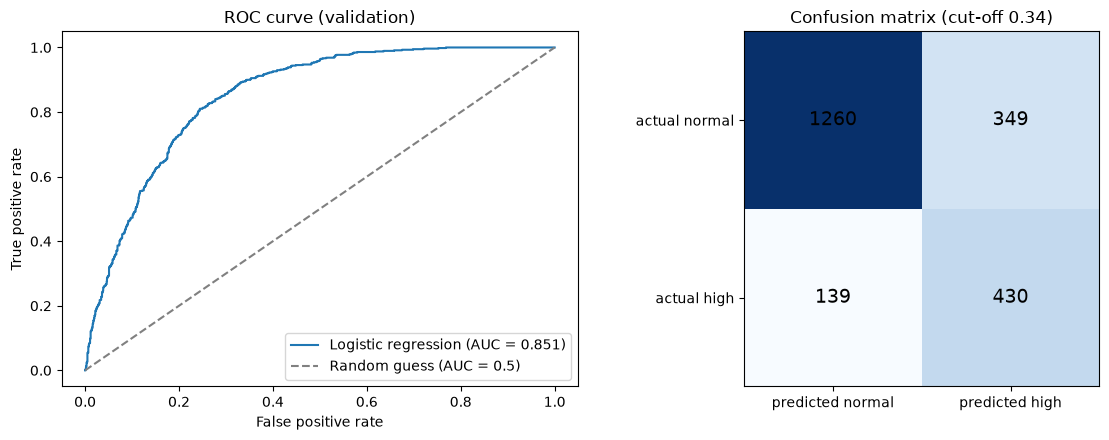

In [42]:
pred_val = (p_val >= BEST_CUT).astype(int)
print(f"Accuracy = {accuracy_score(y5_val, pred_val):.3f}")
print(f"F1-score = {f1_score(y5_val, pred_val):.3f}")
print(f"ROC-AUC  = {roc_auc_score(y5_val, p_val):.3f}")
print(f"(Train ROC-AUC = {roc_auc_score(y5_train, p_train):.3f})")
print(f"Baseline 'never high' accuracy = {1 - y5_val.mean():.3f}")
print(f"F1 at default 0.5 cut-off = {f1_score(y5_val, p_val >= 0.5):.3f}")

cm = confusion_matrix(y5_val, pred_val)
fpr, tpr, _ = roc_curve(y5_val, p_val)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, label=f"Logistic regression (AUC = {roc_auc_score(y5_val, p_val):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Random guess (AUC = 0.5)")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve (validation)"); axes[0].legend()
axes[1].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["predicted normal", "predicted high"])
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(["actual normal", "actual high"])
axes[1].set_title(f"Confusion matrix (cut-off {BEST_CUT})")
plt.tight_layout()
plt.savefig("figures/phase5_evaluation.png", dpi=120)
plt.show()

In [43]:
def auc_with(cols, y_tr, y_va):
    idx = [0] + [j for j, n in enumerate(surviving_features, 1) if any(n.startswith(c) for c in cols)]
    w, _ = logistic_gd(C_tr[:, idx], y_tr, lr=1.0)
    return roc_auc_score(y_va, sigmoid(C_va[:, idx] @ w))

y_global_val = (val_df["cnt"] > median_cnt).astype(int).values
hw_thr = train_df.groupby(["hr", "workingday"])["cnt"].quantile(0.75).rename("threshold")
y_hw_train = (train_df["cnt"] > train_df.join(hw_thr, on=["hr", "workingday"])["threshold"]).astype(int).values
y_hw_val   = (val_df["cnt"]   > val_df.join(hw_thr, on=["hr", "workingday"])["threshold"]).astype(int).values

rows = []
for name, (ytr, yva) in {"Global median": (y_global_train.values, y_global_val),
                         "Per hour × working day": (y_hw_train, y_hw_val),
                         "Per year × hour × working day (chosen)": (y5_train, y5_val)}.items():
    rows.append({"definition": name,
                 "AUC using hour only": auc_with(["hr_"], ytr, yva),
                 "AUC using year only": auc_with(["yr"], ytr, yva)})
pd.DataFrame(rows).round(3)

,definition,AUC using hour only,AUC using year only
0,Global median,0.906,0.593
1,Per hour × working day,0.483,0.759
2,Per year × hour × working day (chosen),0.523,0.491


### Outcome
A global threshold (cnt > 145) labelled 98% of working-day 8am hours as "high" and 0% of 3am hours —
an hour-only classifier reached AUC 0.906 on it, so the label just encoded the clock. Making the threshold
relative to hour × working day exposed a second bias (year alone: AUC 0.759, from 2011→2012 growth);
adding the year removed both (hour-only 0.523, year-only 0.491). The final classifier, using only Phase 4's
75 surviving features, reaches ROC-AUC 0.851, F1 0.638 (cut-off 0.34 chosen on training data) and
accuracy 0.776 vs a 0.739 "never high" baseline. Train AUC 0.849 ≈ validation, so no overfitting.
Surprise: the strongest drivers are temperature and late-summer/autumn months, not the hour.

### Pipeline retrospective
| Phase | Consumed | Produced | Key numbers |
|---|---|---|---|
| 1 – Gradient descent | Seeded split (seed 36662) | 76 weights, lr = 0.1, 2,071 iterations | Val R² 0.871, RMSE 64.4; 0.3 diverges (limit 0.273) |
| 2 – Polynomial | Phase 1 weights as init | Degree 3 on temp, hum, windspeed (91 features) | Val R² 0.905, RMSE 55.3; loss 0.1220 → 0.1107 |
| 3 – Bias-variance | Degree 3 | "Slight bias, no overfitting"; degree 3 kept | Gap 0.007; chrono R² 0.904 but RMSE 67.6; day-19 R² 0.891 |
| 4 – Regularization | Diagnosis + degree 3 | λ = 0.001 per method; 4 redundant columns dropped | Lasso val R² 0.912, RMSE 53.2; 75 features from 8 columns |
| 5 – Logistic | 75 surviving features | Classifier, cut-off 0.34 | ROC-AUC 0.851, F1 0.638, accuracy 0.776 |